# Houlsby Adapter
IndoBERT (`indobenchmark/indobert-base-p2`) | data sizes 5 / 10 / 50 / 100% | 5 seeds.

Two bottleneck adapters per layer (after attention and after the feed-forward block), via the `adapters` library. `reduction_factor=12` gives a 64-dim bottleneck.

In [ ]:
!pip install -q datasets==5.0.1, accelerate==1.14.0, adapters==1.3.0
!pip install -q -U scikit-learn

import transformers, datasets, peft, accelerate, torch
print("transformers:", transformers.__version__, " (pinned)")
print("peft        :", peft.__version__, " (pinned)")
print("datasets    :", datasets.__version__, " (pinned)")
print("accelerate  :", accelerate.__version__, " (pinned)")
print("torch       :", torch.__version__, " (Colab-provided)")
print("CUDA avail  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0), " <- keep the same GPU type across methods")

transformers: 4.57.6  (pinned)
peft        : 0.21.1  (pinned)
datasets    : 5.0.1  (pinned)
accelerate  : 1.14.0  (pinned)
torch       : 2.11.0+cu130  (Colab-provided)
CUDA avail  : True
GPU         : Tesla T4  <- keep the same GPU type across methods


In [12]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/thesis/code')   # folder containing utils.py
from utils import *

print("Data root    :", DATA_ROOT)
print("Results file :", RESULTS_PATH)
print("Seeds        :", SEEDS)
print("Data sizes   :", DATA_SIZES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data root    : /content/drive/MyDrive/thesis/data
Results file : /content/drive/MyDrive/thesis/results.csv
Seeds        : [42, 123, 456, 789, 2026]
Data sizes   : [100, 50, 10]


### Check data and progress

In [ ]:
validate_data_sizes()  
print()
print_status()    

 size_%                                folder  rows  actual_%_of_full  hoax_%
     10 /content/drive/MyDrive/thesis/data/10   848              10.0    50.0
     50 /content/drive/MyDrive/thesis/data/50  4244              50.0    50.0
    100    /content/drive/MyDrive/thesis/data  8486             100.0    50.0

val rows: 1212 | test rows: 2426 | full train rows: 8486
evaluation interval (steps per full-data epoch): 531
Data checks passed.

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
BitFit       5    5    5
FFT          5    5    5
Houlsby      5    5    5
IA3          5    5    5
LoRA         5    5    5
Total: 75 / 75 for methods present


### Model definition
`DoubleSeqBnConfig` = Houlsby-style.

In [14]:
import adapters
from adapters import DoubleSeqBnConfig

REDUCTION_FACTOR = 12   # 768 / 12 = 64-dim bottleneck
ADAPTER_NAME = "houlsby_adapter"

def build_houlsby_model():
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID
    )
    adapters.init(model)
    model.add_adapter(ADAPTER_NAME, config=DoubleSeqBnConfig(reduction_factor=REDUCTION_FACTOR))
    model.set_active_adapters(ADAPTER_NAME)
    model.train_adapter(ADAPTER_NAME)   # prints the harmless warning described above

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"trainable params: {trainable:,} || all params: {total:,} || trainable%: {100*trainable/total:.4f}")
    assert any(n.startswith("classifier") and p.requires_grad for n, p in model.named_parameters()), \
        "classifier head is frozen -- the model cannot learn the task"
    return model

### Run all data sizes and seeds
LR = 1e-4. Already-logged runs are skipped, so you can stop and re-run this cell after a disconnect. Set `RUN_SIZES = [100]` to do just the headline data size first.

In [ ]:
METHOD_NAME = "Houlsby"
LEARNING_RATE = 1e-4
TAG = "main"           
RUN_SIZES = DATA_SIZES 
RUN_SEEDS = SEEDS

In [16]:
for size in RUN_SIZES:
    for seed in RUN_SEEDS:
        run_experiment(
            method_name=METHOD_NAME,
            seed=seed,
            model_init_fn=build_houlsby_model,
            learning_rate=LEARNING_RATE,
            data_size=size,
            tag=TAG,
        )

print()
print_status(tag=TAG)

[skip] Houlsby data=100% seed=42 tag=main already logged
[skip] Houlsby data=100% seed=123 tag=main already logged
[skip] Houlsby data=100% seed=456 tag=main already logged
[skip] Houlsby data=100% seed=789 tag=main already logged
[skip] Houlsby data=100% seed=2026 tag=main already logged
[skip] Houlsby data=50% seed=42 tag=main already logged
[skip] Houlsby data=50% seed=123 tag=main already logged
[skip] Houlsby data=50% seed=456 tag=main already logged
[skip] Houlsby data=50% seed=789 tag=main already logged
[skip] Houlsby data=50% seed=2026 tag=main already logged
[skip] Houlsby data=10% seed=42 tag=main already logged
[skip] Houlsby data=10% seed=123 tag=main already logged
[skip] Houlsby data=10% seed=456 tag=main already logged
[skip] Houlsby data=10% seed=789 tag=main already logged
[skip] Houlsby data=10% seed=2026 tag=main already logged

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
BitFit       5    5    5


### Training curves
One seed per data size (the first in `RUN_SEEDS`). X-axis is the training step; the dashed line marks the checkpoint restored for test evaluation.

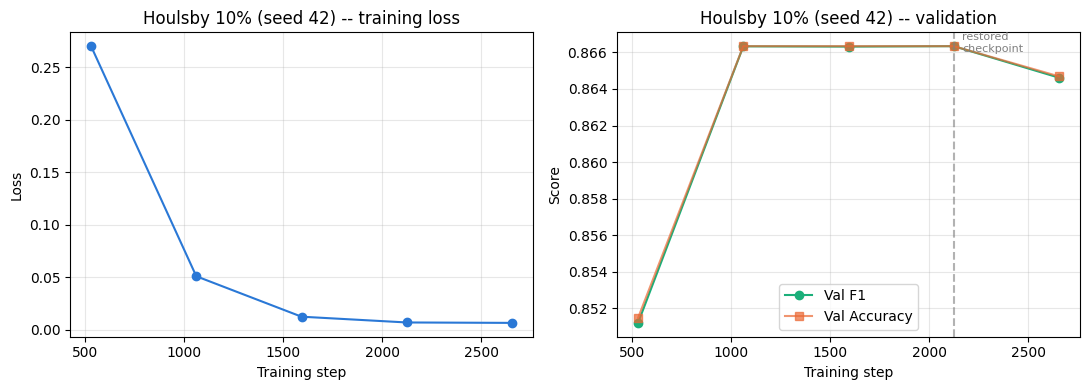

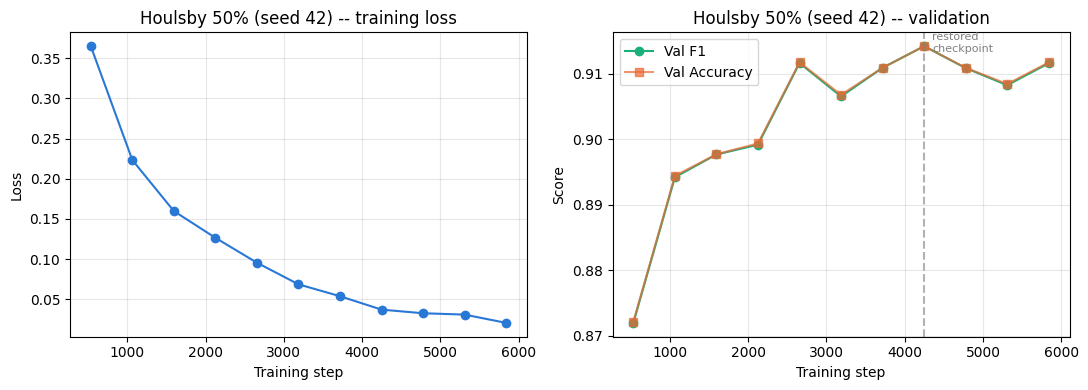

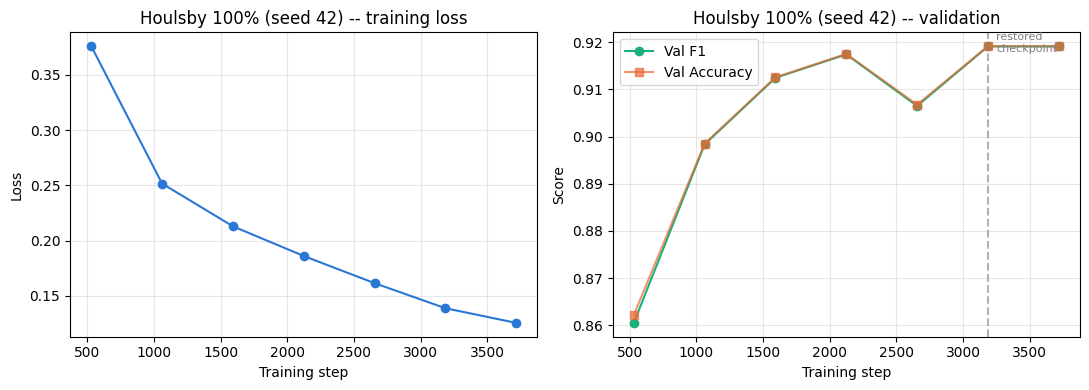

In [17]:
for size in sorted(RUN_SIZES):
    plot_training_curves(METHOD_NAME, RUN_SEEDS[0], size, TAG)

### Consistency across seeds
Validation F1 for all seeds overlaid, one chart per data size.

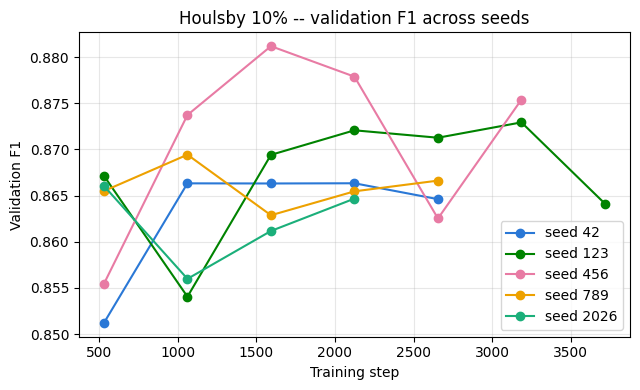

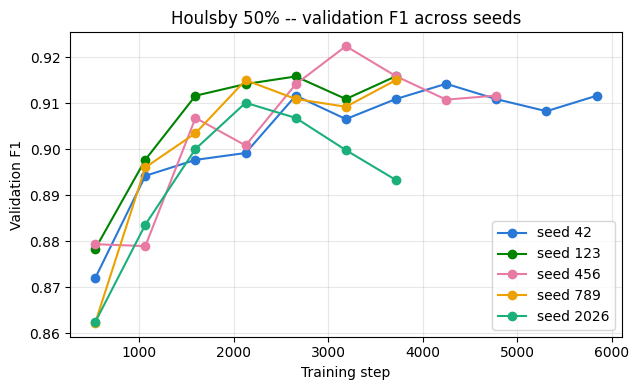

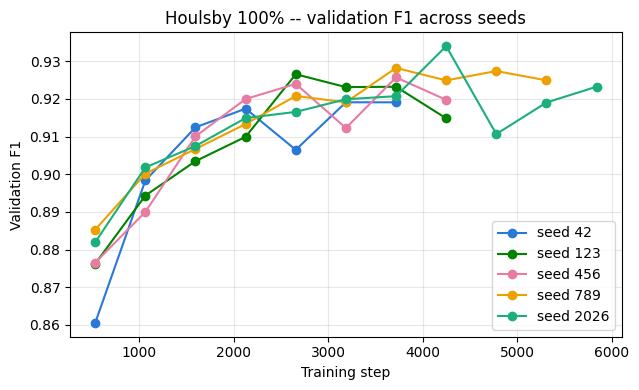

In [18]:
for size in sorted(RUN_SIZES):
    plot_seeds_overlay(METHOD_NAME, size, tag=TAG)

### Confusion matrices
Pooled over seeds, one per data size.

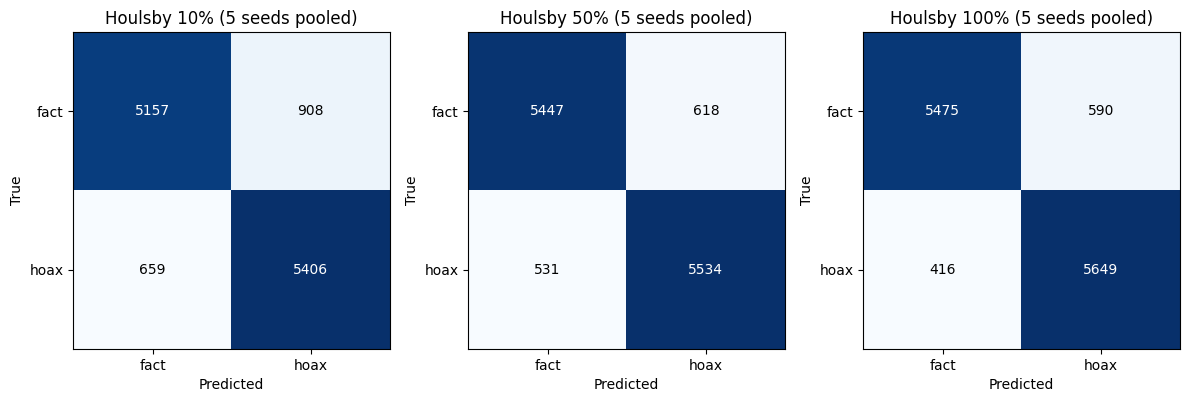

In [19]:
plot_confusion_matrices_by_size(METHOD_NAME, tag=TAG)

### Summary by data size
Mean +/- std over seeds: test vs. validation F1, generalization gap, training time.

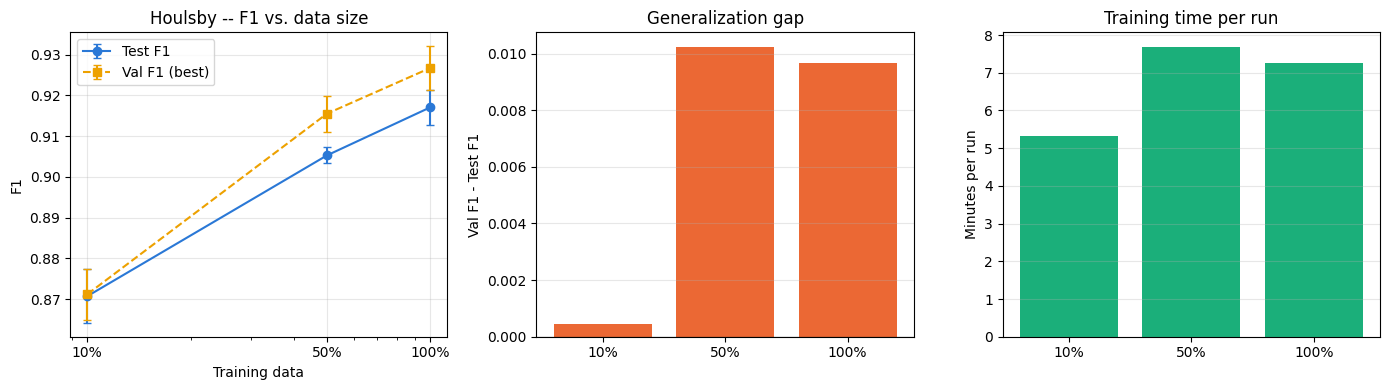

 data_size  seed  best_val_f1  accuracy       f1  trainable_pct  peak_vram_gb  total_time_s  epochs_run  steps_run
        10    42       0.8663  0.867683 0.867683         1.8773         0.781         305.2           5       2655
        10   123       0.8729  0.875103 0.875100         1.8773         0.781         355.5           7       3717
        10   456       0.8812  0.879637 0.879616         1.8773         0.781         348.3           6       3186
        10   789       0.8694  0.868096 0.867959         1.8773         0.781         354.9           5       2655
        10  2026       0.8661  0.863561 0.863210         1.8773         0.781         235.6           4       2124
        50    42       0.9142  0.906430 0.906430         1.8773         0.863         570.8          11       5841
        50   123       0.9158  0.906018 0.906018         1.8773         0.863         397.9           7       3717
        50   456       0.9224  0.905194 0.905136         1.8773         0.863   

In [20]:
plot_method_summary(METHOD_NAME, tag=TAG)